# 04 — Modelo global

**Objetivo.** Elegir y justificar el modelo global de la Fase 4, y comprobar con datos las dos
afirmaciones sobre las que se apoya la contribución del TFM: que la cabeza **(μ, log σ²)** no
cuesta precisión, y que la alarma **P(y < 70) > α** detecta hipoglucemias que `μ < 70` no ve.

In [1]:
%load_ext autoreload
%autoreload 2

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tfm.eval.alarm import alarm_analysis, operating_curve, pick_alpha, predictions_from_experiment
from tfm.eval.calibration import cohort_calibration
from tfm.eval.compare import comparison_table
from tfm.eval.protocol import scorable_events_by_patient
from tfm.paths import RESULTS_DIR
from tfm.viz import FIG_WIDTH_FULL, INK, ROLE
from tfm.viz.plots import set_style, save_figure

set_style()
pd.set_option("display.width", 150)

FASE4 = {
    "20260916-global-bigru": "BiGRU (NLL)",
    "20260916-global-transformer": "Transformer (NLL)",
    "20260916-global-bigru-mse": "BiGRU (MSE)",
    "20260916-global-bigru-univariante": "BiGRU univariante",
    "20260916-global-bigru-historia24": "BiGRU historia 120 min",
}
BASELINES = {
    "20260915-baseline-persistencia": "persistencia",
    "20260916-baseline-ridge": "ridge",
    "20260916-baseline-lstm-global": "LSTM global",
}
SEMILLAS = (0, 1, 2)

## 1. Tabla de la Fase 4

Todas las cifras con media ± desviación sobre 3 semillas. `recall` aquí es todavía el de la
regla `μ < 70`: la alarma probabilística llega en la sección 3.

In [2]:
filas = []
for exp, nombre in {**BASELINES, **FASE4}.items():
    d = json.loads((RESULTS_DIR / exp / "metrics.json").read_text())
    for h in ("30", "60"):
        a = d.get("aggregate", {}).get(h)
        if a is None:   # la persistencia no tiene bloque agregado
            s = d["by_horizon"][h]["summary"]
            a = {"rmse_pooled": {"mean": s["rmse_pooled"], "std": 0.0},
                 "event_recall": {"mean": s["pooled_event_recall"]["point"], "std": 0.0,
                                  "n_events": s["pooled_event_recall"]["n"]}}
        filas.append({
            "modelo": nombre, "PH": int(h),
            "RMSE": a["rmse_pooled"]["mean"], "RMSE sd": a["rmse_pooled"]["std"],
            "recall μ<70": a["event_recall"]["mean"], "recall sd": a["event_recall"]["std"],
            "n_eventos": a["event_recall"]["n_events"],
            "parámetros": d.get("n_parameters", 0),
        })
tabla = pd.DataFrame(filas)
for h in (30, 60):
    print(f"\n===== PH {h} min =====")
    print(tabla[tabla.PH == h].drop(columns="PH").to_string(index=False,
          float_format=lambda x: f"{x:8.3f}"))


===== PH 30 min =====
                modelo     RMSE  RMSE sd  recall μ<70  recall sd  n_eventos  parámetros
          persistencia   23.498    0.000        0.098      0.000         61           0
                 ridge   19.412    0.000        0.279      0.000         61           0
           LSTM global   19.024    0.071        0.038      0.009         61           0
           BiGRU (NLL)   18.973    0.103        0.186      0.062         61      110084
     Transformer (NLL)   19.535    0.074        0.137      0.124         61      400772
           BiGRU (MSE)   18.967    0.089        0.055      0.034         61      110084
     BiGRU univariante   20.258    0.207        0.011      0.009         61      101636
BiGRU historia 120 min   19.006    0.040        0.089      0.031         56      110084

===== PH 60 min =====
                modelo     RMSE  RMSE sd  recall μ<70  recall sd  n_eventos  parámetros
          persistencia   38.550    0.000        0.066      0.000         6

El BiGRU con NLL es el mejor en RMSE de todo el proyecto (18,97 y 31,48) y
bate a las cuatro líneas base. Pero su recall con `μ < 70` sigue siendo 0,186, **por debajo del
0,279 del ridge lineal**. Con la regla de alarma clásica, la Fase 4 todavía no resuelve el
problema clínico: solo mejora el error medio.

Dos filas piden cuidado. El **Transformer** usa 3,6 veces más parámetros para un RMSE peor. Y
la **ablación de historia tiene n=56**, no 61, así que su recall no se compara directamente.

## 2. ¿Cuesta algo la verosimilitud?

`BiGRU (NLL)` y `BiGRU (MSE)` comparten arquitectura, datos, semillas y protocolo. Lo único
distinto es la pérdida.

In [3]:
comp = tabla[tabla.modelo.isin(["BiGRU (NLL)", "BiGRU (MSE)"])]
print(comp[["modelo", "PH", "RMSE", "RMSE sd", "recall μ<70", "recall sd"]]
      .to_string(index=False, float_format=lambda x: f"{x:8.3f}"))

for h in (30, 60):
    d = comp[comp.PH == h].set_index("modelo")
    dif_rmse = d.loc["BiGRU (NLL)", "RMSE"] - d.loc["BiGRU (MSE)", "RMSE"]
    ratio = d.loc["BiGRU (NLL)", "recall μ<70"] / max(d.loc["BiGRU (MSE)", "recall μ<70"], 1e-9)
    print(f"\nPH {h}: diferencia de RMSE {dif_rmse:+.3f} mg/dL | recall x{ratio:.1f}")

     modelo  PH     RMSE  RMSE sd  recall μ<70  recall sd
BiGRU (NLL)  30   18.973    0.103        0.186      0.062
BiGRU (NLL)  60   31.480    0.209        0.027      0.009
BiGRU (MSE)  30   18.967    0.089        0.055      0.034
BiGRU (MSE)  60   31.478    0.173        0.016      0.000

PH 30: diferencia de RMSE +0.006 mg/dL | recall x3.4

PH 60: diferencia de RMSE +0.002 mg/dL | recall x1.7


El RMSE es **idéntico hasta la segunda decimal** (18,97 y 31,48 en ambos),
mientras que el recall con la misma regla `μ < 70` se multiplica por 3,4 a 30 min y por 3,4 a
60 min al entrenar con la verosimilitud.

La verosimilitud **no cuesta precisión y mejora la detección**. El mecanismo es la ponderación
β de Seitzer et al.: al reescalar cada término por σ^(2β), la pérdida pesa más las regiones de
alta varianza, que son justamente las excursiones hipoglucémicas. Y el modelo con MSE **no
puede emitir la alarma probabilística en absoluto**, porque no tiene σ.

## 3. La alarma probabilística

Aquí está el argumento central de la Fase 4. Se barre α y se mide, sobre los mismos 61 eventos
y la misma tolerancia, cuántos detecta la regla `P(y < 70) > α` y a qué precio en falsas
alarmas.

In [4]:
by_h = predictions_from_experiment("20260916-global-bigru", seed=0)
eventos = scorable_events_by_patient(by_h)
curvas = {h: operating_curve(by_h[h], eventos) for h in (30, 60)}

for h, c in curvas.items():
    print(f"\n===== PH {h} min | alarma P(y<70) > alpha =====")
    print(c.to_string(index=False, float_format=lambda x: f"{x:8.3f}"))
    print("  presupuesto 1 falsa alarma/día ->", pick_alpha(c, 1.0))


===== PH 30 min | alarma P(y<70) > alpha =====
   alpha   recall  recall_lo  recall_hi  n_events  false_alarms_per_day  false_alarm_episodes
   0.050    1.000      1.000      1.000        61                 3.417                   422
   0.100    1.000      1.000      1.000        61                 2.413                   298
   0.150    1.000      1.000      1.000        61                 2.049                   253
   0.200    0.967      0.918      1.000        61                 1.555                   192
   0.250    0.951      0.885      1.000        61                 1.255                   155
   0.300    0.787      0.672      0.885        61                 0.956                   118
   0.400    0.295      0.180      0.410        61                 0.567                    70
   0.500    0.115      0.033      0.197        61                 0.211                    26
   0.600    0.033      0.000      0.082        61                 0.178                    22
   0.700    

[PosixPath('memoria/figuras/04_curva_operacion.pdf'),
 PosixPath('memoria/figuras/04_curva_operacion.png')]

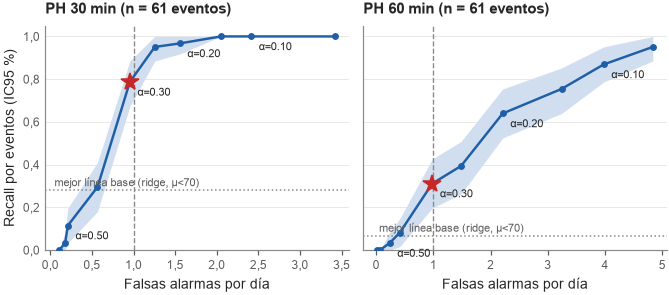

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.9), sharey=True)
for ax, h in zip(axes, (30, 60)):
    c = curvas[h]
    ax.fill_between(c["false_alarms_per_day"], c["recall_lo"], c["recall_hi"],
                    color=ROLE["modelo_banda"], lw=0)
    ax.plot(c["false_alarms_per_day"], c["recall"], "o-", ms=3.5, color=ROLE["modelo"], zorder=3)
    for _, r in c.iterrows():
        if r["alpha"] in (0.1, 0.2, 0.3, 0.5):
            ax.annotate(f"α={r['alpha']:.2f}", (r["false_alarms_per_day"], r["recall"]),
                        textcoords="offset points", xytext=(5, -9), fontsize=7)
    elegido = pick_alpha(c, 1.0)
    ax.axvline(1.0, color=INK["tenue"], ls="--", lw=0.9)
    ax.plot([elegido["false_alarms_per_day"]], [elegido["recall"]], "*",
            ms=12, color=ROLE["hipo"], zorder=4)
    # Referencia: la mejor linea base de la Fase 3 con la regla mu<70.
    ref = 0.279 if h == 30 else 0.066
    ax.axhline(ref, color=INK["tenue"], ls=":", lw=1)
    ax.text(0.05, ref + 0.02, "mejor línea base (ridge, μ<70)", fontsize=7, color=INK["secundario"])
    ax.set_xlabel("Falsas alarmas por día")
    ax.set_title(f"PH {h} min (n = 61 eventos)")
    ax.set_ylim(0, 1.05)
axes[0].set_ylabel("Recall por eventos (IC95 %)")
fig.tight_layout()
save_figure(fig, "04_curva_operacion")

Con un presupuesto de una falsa alarma al día (α ≈ 0,30):

- **a 30 min el recall pasa de 0,186 a 0,787**, muy por encima del 0,279 del mejor baseline;
- **a 60 min pasa de 0,027 a 0,311**, donde ninguna línea base superaba 0,066.

Y lo que la curva añade sobre un número suelto: **α es un mando**. Un servicio dispuesto a
tolerar 2,4 falsas alarmas al día alcanza recall 1,000 a 30 min; uno que solo tolere 0,2 se
queda en 0,115. Esa elección es clínica, no del modelo, y es exactamente lo que la regla
`μ < 70` no permite.

### 3.1 Estabilidad entre semillas

Antes de dar por bueno el 0,787: α* se reelige en cada semilla bajo el presupuesto, y con 61
eventos esa elección se mueve.

In [6]:
filas = []
for exp, nombre in (("20260916-global-bigru", "BiGRU"),
                    ("20260916-global-transformer", "Transformer")):
    for h in ("30", "60"):
        for s in SEMILLAS:
            a = alarm_analysis(exp, seed=s)[h]["chosen"]["1.0"]
            filas.append({"modelo": nombre, "PH": int(h), "semilla": s,
                          "alpha*": a["alpha"], "recall": a["recall"],
                          "FA/día": a["false_alarms_per_day"]})
estab = pd.DataFrame(filas)
resumen = (estab.groupby(["modelo", "PH"])["recall"]
           .agg(["mean", "std", "min", "max"]).round(3))
print(estab.to_string(index=False, float_format=lambda x: f"{x:7.3f}"))
print("\nResumen sobre 3 semillas:")
print(resumen.to_string())

     modelo  PH  semilla  alpha*  recall  FA/día
      BiGRU  30        0   0.300   0.787   0.956
      BiGRU  30        1   0.400   0.459   0.737
      BiGRU  30        2   0.300   0.852   0.996
      BiGRU  60        0   0.300   0.311   0.980
      BiGRU  60        1   0.300   0.262   0.988
      BiGRU  60        2   0.300   0.262   0.875
Transformer  30        0   0.200   0.885   0.996
Transformer  30        1   0.300   0.754   0.875
Transformer  30        2   0.250   0.820   0.891
Transformer  60        0   0.300   0.148   0.737
Transformer  60        1   0.300   0.230   0.850
Transformer  60        2   0.300   0.180   0.696

Resumen sobre 3 semillas:
                 mean    std    min    max
modelo      PH                            
BiGRU       30  0.699  0.211  0.459  0.852
            60  0.279  0.028  0.262  0.311
Transformer 30  0.820  0.066  0.754  0.885
            60  0.186  0.041  0.148  0.230


El BiGRU a 30 min va de **0,459 a 0,852** según la semilla: media
0,699 ± 0,211. **La cifra honesta para la memoria es la media, no el 0,787 de la mejor
semilla.** A 60 min es mucho más estable (0,279 ± 0,028).

El Transformer, en cambio, es más estable a 30 min (0,820 ± 0,066) y peor a 60 (0,186 ± 0,041).
Los intervalos se solapan casi siempre: con n=61 **no hay base para declarar un ganador por
recall**.

## 4. ¿Es creíble la σ que emite el modelo?

Si la distribución predicha no está calibrada, `P(y<70) > α` es solo otro umbral arbitrario con
más pasos intermedios.

In [7]:
filas = []
for h in (30, 60):
    cal = cohort_calibration(by_h[h])
    for c in cal["coverage"]:
        filas.append({"PH": h, "nivel nominal": c["level"], "PICP": c["picp"],
                      "error": c["calibration_error"], "MPIW (mg/dL)": c["mpiw"]})
    print(f"PH {h}: CRPS {cal['crps']:.2f} mg/dL | σ media {cal['sigma_mean']:.1f} "
          f"| IQR {cal['sigma_iqr']:.1f} | rango {cal['sigma_min']:.1f}–{cal['sigma_max']:.1f}")
calib = pd.DataFrame(filas)
print()
print(calib.to_string(index=False, float_format=lambda x: f"{x:8.3f}"))

PH 30: CRPS 9.75 mg/dL | σ media 19.9 | IQR 7.7 | rango 10.3–105.3
PH 60: CRPS 16.59 mg/dL | σ media 31.7 | IQR 12.0 | rango 17.2–103.3

 PH  nivel nominal     PICP    error  MPIW (mg/dL)
 30          0.500    0.627    0.127        26.853
 30          0.800    0.878    0.078        51.021
 30          0.900    0.938    0.038        65.485
 30          0.950    0.963    0.013        78.030
 60          0.500    0.578    0.078        42.763
 60          0.800    0.854    0.054        81.251
 60          0.900    0.924    0.024       104.284
 60          0.950    0.956    0.006       124.262


[PosixPath('memoria/figuras/04_calibracion.pdf'),
 PosixPath('memoria/figuras/04_calibracion.png')]

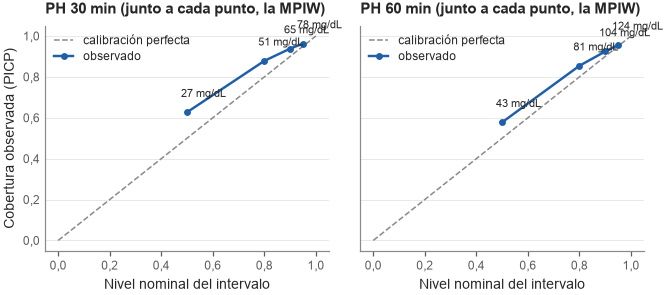

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(FIG_WIDTH_FULL, 2.9), sharey=True)
for ax, h in zip(axes, (30, 60)):
    d = calib[calib.PH == h]
    ax.plot([0, 1], [0, 1], ls="--", color=INK["tenue"], lw=1, label="calibración perfecta")
    ax.plot(d["nivel nominal"], d["PICP"], "o-", ms=3.5, color=ROLE["modelo"], label="observado")
    for _, r in d.iterrows():
        ax.annotate(f"{r['MPIW (mg/dL)']:.0f} mg/dL",
                    (r["nivel nominal"], r["PICP"]), textcoords="offset points",
                    xytext=(-4, 10), fontsize=7)
    ax.set_xlabel("Nivel nominal del intervalo")
    ax.set_title(f"PH {h} min (junto a cada punto, la MPIW)")
    ax.legend(loc="upper left")
axes[0].set_ylabel("Cobertura observada (PICP)")
fig.tight_layout()
save_figure(fig, "04_calibracion")

La cobertura es **buena en la cola y sobrecubre en el centro**: 0,963
frente a 0,95 nominal, pero 0,627 frente a 0,50. Los residuos son más apuntados que una
gaussiana — muchos errores pequeños y algunos grandes — así que el intervalo central sale
demasiado ancho.

Para la alarma esto importa poco, porque lo que usa es la masa de la cola por debajo de 70, que
es donde la calibración es buena. **Pero el intervalo central no debe presentarse en la memoria
como calibrado**, y el MPIW al 95 % (78 mg/dL a 30 min, **124 mg/dL a 60 min**) es demasiado
ancho para enseñárselo a un paciente como banda de confianza. La utilidad está en la
probabilidad puntual, no en la banda.

σ no está colapsada: IQR de 7,7 mg/dL y rango 10,3–105,3, así que la cabeza de varianza aprende
algo dependiente de la entrada.

## 5. Ablaciones

Tres preguntas: ¿aportan las features?, ¿aporta más historia?, ¿aporta la autoatención?

[PosixPath('memoria/figuras/04_ablaciones.pdf'),
 PosixPath('memoria/figuras/04_ablaciones.png')]

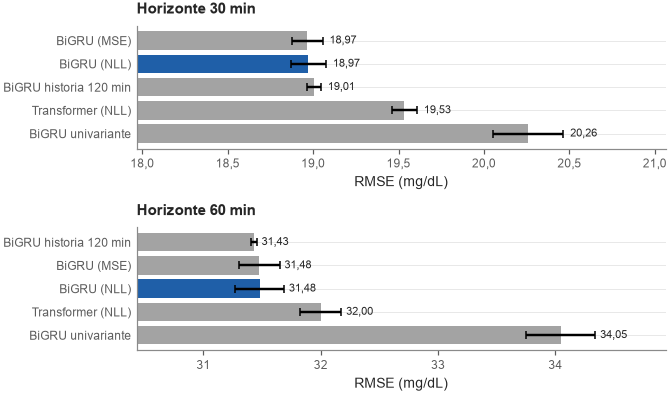

In [9]:
# One row per horizon: each panel sorts the models by its own RMSE, so each keeps its labels.
fig, axes = plt.subplots(2, 1, figsize=(FIG_WIDTH_FULL, 3.8))
abl = tabla[tabla.modelo.str.startswith(("BiGRU", "Transformer"))]
for ax, h in zip(axes, (30, 60)):
    d = abl[abl.PH == h].sort_values("RMSE")
    colores = [ROLE["modelo"] if m == "BiGRU (NLL)" else ROLE["referencia"] for m in d.modelo]
    ax.barh(d.modelo, d.RMSE, xerr=d["RMSE sd"], color=colores)
    ax.invert_yaxis()
    ax.set_xlim(left=min(d.RMSE) - 1)
    ax.set_xlabel("RMSE (mg/dL)")
    ax.set_title(f"Horizonte {h} min")
    for y, (v, sd) in enumerate(zip(d.RMSE, d["RMSE sd"].fillna(0))):
        ax.text(v + sd + 0.04, y, f"{v:.2f}".replace(".", ","), va="center", fontsize=7,
                color=INK["texto"])
    ax.set_xlim(right=max(d.RMSE + d["RMSE sd"].fillna(0)) + 0.6)
fig.tight_layout()
save_figure(fig, "04_ablaciones")

- **Las features aportan mucho.** Quitarlas (univariante) empeora el RMSE en 1,29 mg/dL a 30 min
  y hunde el recall con μ<70 de 0,186 a 0,011. Justifica el trabajo de reconstrucción de
  insulina e hidratos de la Fase 2 con evidencia, no por convención.
- **Más historia no aporta nada.** 120 min da 19,01 frente a 18,97, dentro del ruido entre
  semillas. Se mantiene la ventana de 60 min, y ahora con un argumento medido. Tiene sentido
  fisiológico: IOB y COB ya resumen el pasado lejano mejor que 12 pasos más de CGM.
- **La autoatención no aporta sobre 12 pasos.** El Transformer pierde en NLL de validación
  (−0,0962 frente a −0,1037) y en RMSE, con 3,6 veces más parámetros.

## 6. Conclusiones

- **Modelo elegido: BiGRU (1 capa, 128 unidades) con cabeza (μ, log σ²) y pérdida NLL β=0,5.**
  Mejor NLL de validación, mejor RMSE del proyecto (18,97 / 31,48), 3,6 veces menos parámetros
  que el Transformer — lo que importa cuando la Fase 5 tenga que hacer fine-tuning con un día
  de datos — y ventaja clara en el horizonte de 60 min.

- **La verosimilitud es gratis en precisión y rentable en clínica**: mismo RMSE que MSE hasta la
  segunda decimal, recall ×3,4 con la misma regla de alarma, y además habilita la alarma
  probabilística, que el modelo con MSE no puede emitir.

- **La alarma P(y<70) > α es el resultado de la fase.** Con 1 falsa alarma/día:
  recall **0,787** a 30 min (frente a 0,186 con μ<70 y 0,279 del mejor baseline) y **0,311** a
  60 min (frente a 0,027 y 0,066). α es un mando clínico, no un hiperparámetro.